<a href="https://colab.research.google.com/github/NOWSHIDHAKI/Brain-Tumor-Predection/blob/main/Brain_Tumor_ViT_Colab_FIXED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Brain Tumor Classification using Vision Transformer (ViT)

Classifies brain MRI scans into **4 categories**:
| Class | Tumor? | Severity |
|---|---|---|
| Glioma | ✅ Yes | 🔴 High |
| Meningioma | ✅ Yes | 🟡 Moderate |
| Pituitary | ✅ Yes | 🟡 Moderate |
| No Tumor | ❌ No | ✅ Normal |

---
### ⚡ FIRST — Enable GPU:
> **Runtime → Change runtime type → T4 GPU → Save → Connect**

---
> ⚠️ *Disclaimer: AI-assisted only. Always consult a qualified medical professional.*

## 📦 Cell 1 — Install Libraries

In [ ]:
!pip install timm opencv-python-headless scikit-learn seaborn -q
print('✅ Libraries installed!')

✅ Libraries installed!


## 📂 Cell 2 — Download Dataset via Kaggle API

### How to get your `kaggle.json`:
1. Go to 👉 [https://www.kaggle.com](https://www.kaggle.com) and log in
2. Click your **profile picture** → **Settings**
3. Scroll to **API** section → Click **'Create New Token'**
4. A file called `kaggle.json` will download to your PC
5. Run this cell → click **Choose Files** → upload that `kaggle.json`

> ✅ This is much faster than uploading the full zip!

In [ ]:
# ════════════════════════════════════════════════════════
# Cell 2 — Download Dataset using kagglehub (FIXED ✅)
# ════════════════════════════════════════════════════════
import os

# ── Step 1: Install kagglehub ────────────────────────────
!pip install kagglehub -q

# ── Step 2: Set your token ──────────────────────────────
# Paste your KGAT_ token from Kaggle → Settings → API
os.environ["KAGGLE_API_TOKEN"] = "KGAT_80d2679a0cd5e2f6b75f3d5d069db088"  # ← your token

# ── Step 3: Download dataset ────────────────────────────
import kagglehub

print("📥 Downloading Brain Tumor MRI Dataset...")
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print(f"✅ Downloaded to: {path}")

# ── Step 4: Find Training/Testing folders ───────────────
TRAIN_DIR = None
TEST_DIR  = None
for root, dirs, _ in os.walk(path):
    if "Training" in dirs and "Testing" in dirs:
        TRAIN_DIR = os.path.join(root, "Training")
        TEST_DIR  = os.path.join(root, "Testing")
        break

# Fallback: search one level deeper
if TRAIN_DIR is None:
    for root, dirs, _ in os.walk(path):
        for d in dirs:
            sub = os.path.join(root, d)
            sub_dirs = os.listdir(sub)
            if "Training" in sub_dirs and "Testing" in sub_dirs:
                TRAIN_DIR = os.path.join(sub, "Training")
                TEST_DIR  = os.path.join(sub, "Testing")
                break

print(f"\n📁 Training  : {TRAIN_DIR}")
print(f"📁 Testing   : {TEST_DIR}")
print(f"📁 Classes   : {os.listdir(TRAIN_DIR)}")

📥 Downloading Brain Tumor MRI Dataset...
Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
✅ Downloaded to: /kaggle/input/brain-tumor-mri-dataset

📁 Training  : /kaggle/input/brain-tumor-mri-dataset/Training
📁 Testing   : /kaggle/input/brain-tumor-mri-dataset/Testing
📁 Classes   : ['pituitary', 'notumor', 'meningioma', 'glioma']


## ⚙️ Cell 3 — Imports, Config & Class Info

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import timm
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from PIL import Image
import cv2
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from tqdm.notebook import tqdm
import warnings, os
warnings.filterwarnings('ignore')

# ── GPU Check ───────────────────────────────────────────────
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'🖥️  Device : {device.upper()}')
if device == 'cuda':
    print(f'   GPU    : {torch.cuda.get_device_name(0)}')
    print(f'   Memory : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    print('   ⚠️  No GPU! Go to Runtime → Change runtime type → T4 GPU')

# ── Config ──────────────────────────────────────────────────
CONFIG = {
    'train_dir'   : TRAIN_DIR,
    'test_dir'    : TEST_DIR,
    'model_name'  : 'vit_base_patch16_224',
    'num_classes' : 4,
    'img_size'    : 224,
    'batch_size'  : 32,
    'epochs'      : 15,
    'lr'          : 2e-4,
    'weight_decay': 1e-5,
    'save_path'   : 'brain_tumor_vit_best.pth',
    'num_workers' : 2,
    'device'      : device,
}

CLASS_NAMES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

CLASS_INFO = {
    'Glioma': {
        'emoji'        : '🔴',
        'tumor'        : True,
        'brain_region' : 'Cerebrum / Brainstem / Cerebellum',
        'description'  : 'Tumor from glial cells of the brain/spinal cord. Affects thinking, movement, and bodily functions.',
        'affected_part': 'CEREBRUM (thought, memory, movement), BRAINSTEM (breathing, heart rate), or CEREBELLUM (balance).',
        'severity'     : 'HIGH ⚠️  — Can be malignant (cancerous)',
        'cure_chance'  : {
            'label'  : 'Moderate to Low',
            'percent': '30–60%',
            'details': 'Grade I–II: 60–80% 5-yr survival.\nGrade III: ~30–40%.\nGrade IV (GBM): ~5–10%.\nEarly detection improves outcomes significantly.'
        },
        'treatments': ['Surgical resection', 'Radiation therapy', 'Chemotherapy (Temozolomide)', 'Immunotherapy', 'Tumor Treating Fields (TTFields)'],
    },
    'Meningioma': {
        'emoji'        : '🟡',
        'tumor'        : True,
        'brain_region' : 'Brain Surface / Skull Base / Spinal Cord Covering',
        'description'  : 'Tumor from the meninges — membranes covering the brain. Usually benign and slow-growing.',
        'affected_part': 'OUTER BRAIN SURFACE or SKULL BASE. Presses on nearby regions causing headaches, vision issues, or weakness.',
        'severity'     : 'MODERATE 🟡 — Usually benign; malignant in ~3% of cases',
        'cure_chance'  : {
            'label'  : 'High',
            'percent': '70–90%',
            'details': 'Grade I (Benign): 90%+ survival with surgery.\nGrade II: 50–70% recurrence-free at 5 yrs.\nGrade III: ~50% 5-yr survival.'
        },
        'treatments': ['Active surveillance', 'Surgical resection', 'Gamma Knife / CyberKnife', 'Radiation therapy', 'Symptom medications'],
    },
    'No Tumor': {
        'emoji'        : '✅',
        'tumor'        : False,
        'brain_region' : 'N/A — All regions appear normal',
        'description'  : 'No tumor or abnormality detected. Brain structure is within normal limits.',
        'affected_part': 'No affected region. CEREBRUM, CEREBELLUM, BRAINSTEM — all appear structurally normal.',
        'severity'     : 'NORMAL ✅ — No pathology detected',
        'cure_chance'  : {
            'label'  : 'N/A',
            'percent': '100%',
            'details': 'No tumor detected. No treatment required.'
        },
        'treatments': ['No tumor-specific treatment needed', 'Routine annual MRI monitoring', 'Regular health check-ups'],
    },
    'Pituitary': {
        'emoji'        : '🟡',
        'tumor'        : True,
        'brain_region' : 'Pituitary Gland — Base of Brain (Sella Turcica)',
        'description'  : "Tumor of the pituitary gland — the body's master hormone gland. Usually benign.",
        'affected_part': 'PITUITARY GLAND (sella turcica). May press on OPTIC CHIASM (vision) or HYPOTHALAMUS (body regulation).',
        'severity'     : 'MODERATE 🟡 — Usually benign; significant hormonal effects',
        'cure_chance'  : {
            'label'  : 'High',
            'percent': '75–95%',
            'details': 'Microadenomas (<10mm): 85–95% cure with surgery.\nMacroadenomas: 50–70%.\nProlactinomas: 70–80% controlled with medication alone.'
        },
        'treatments': ['Dopamine agonists (Cabergoline)', 'Transsphenoidal surgery', 'Gamma Knife radiosurgery', 'Hormone replacement', 'MRI monitoring'],
    },
}

print('\n✅ Config and class info ready!')

🖥️  Device : CUDA
   GPU    : Tesla T4
   Memory : 15.6 GB

✅ Config and class info ready!


## 🖼️ Cell 4 — Dataset Loaders & Sample Preview

📊 Training samples : 5600
📊 Testing  samples : 1600
📁 Classes detected : ['glioma', 'meningioma', 'notumor', 'pituitary']


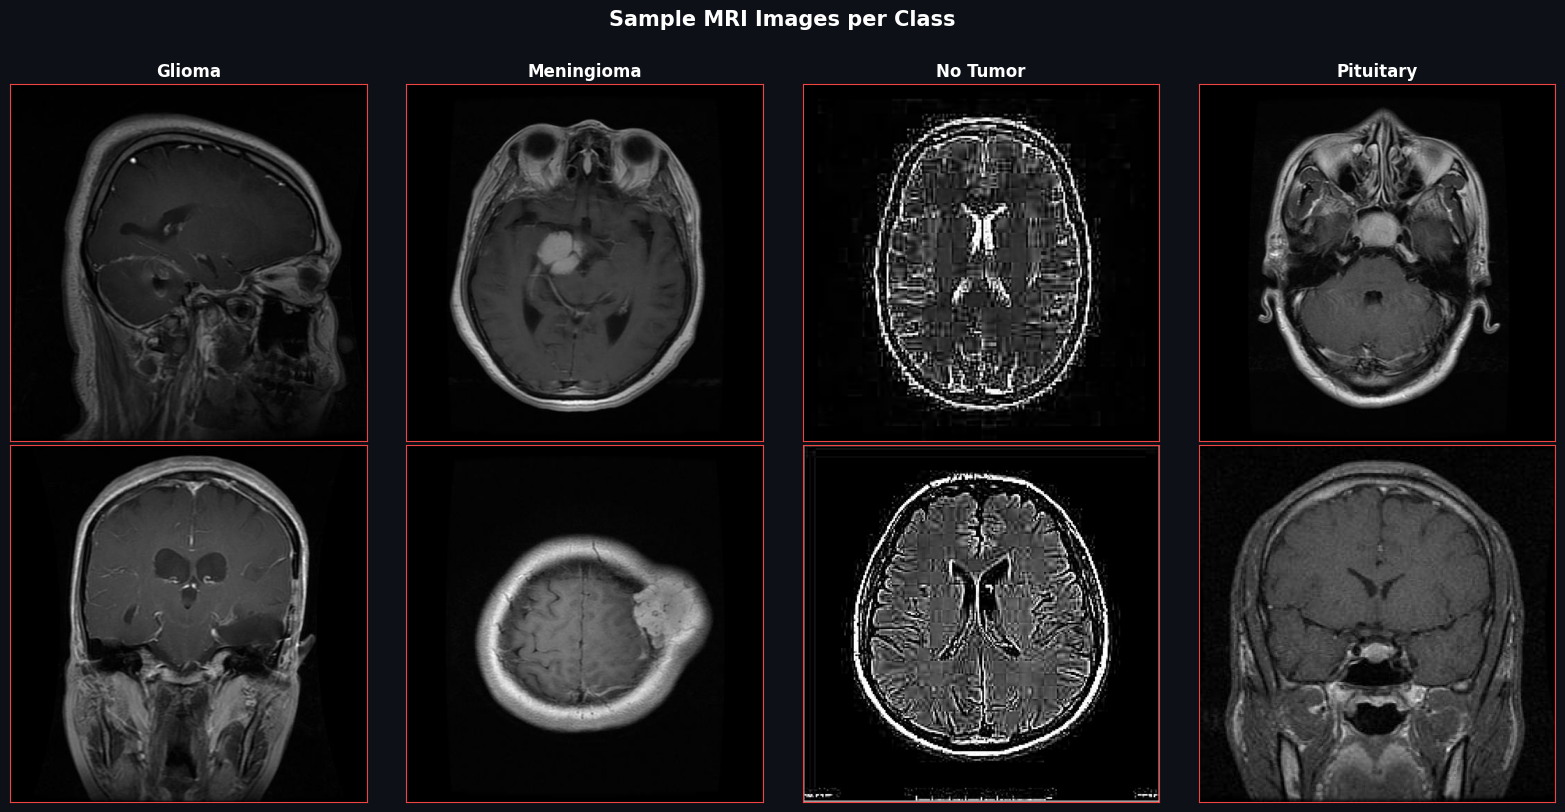

In [ ]:
def get_transforms():
    train_tf = transforms.Compose([
        transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(p=0.1),
        transforms.RandomRotation(20),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.1),
        transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    val_tf = transforms.Compose([
        transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    return train_tf, val_tf

train_tf, val_tf = get_transforms()
train_ds = datasets.ImageFolder(CONFIG['train_dir'], transform=train_tf)
test_ds  = datasets.ImageFolder(CONFIG['test_dir'],  transform=val_tf)

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                          shuffle=True,  num_workers=CONFIG['num_workers'], pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True)

print(f'📊 Training samples : {len(train_ds)}')
print(f'📊 Testing  samples : {len(test_ds)}')
print(f'📁 Classes detected : {train_ds.classes}')

# ── Sample Preview ───────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.patch.set_facecolor('#0d1117')
fig.suptitle('Sample MRI Images per Class', fontsize=15, fontweight='bold', color='white', y=1.01)
for i, cls in enumerate(train_ds.classes):
    cls_dir = os.path.join(CONFIG['train_dir'], cls)
    imgs    = os.listdir(cls_dir)
    for row, idx in enumerate([0, 5]):
        img = Image.open(os.path.join(cls_dir, imgs[idx])).convert('RGB')
        axes[row][i].imshow(img)
        axes[row][i].set_facecolor('#161b22')
        for sp in axes[row][i].spines.values(): sp.set_color('#ef4444')
        axes[row][i].set_xticks([]); axes[row][i].set_yticks([])
        if row == 0:
            axes[row][i].set_title(CLASS_NAMES[i], fontsize=12, fontweight='bold', color='white')
plt.tight_layout()
plt.show()

## 🤖 Cell 5 — Vision Transformer Model

In [ ]:
class BrainTumorViT(nn.Module):
    def __init__(self, num_classes=4, pretrained=True):
        super().__init__()
        self.vit = timm.create_model(
            CONFIG['model_name'], pretrained=pretrained, num_classes=0
        )
        in_features = self.vit.num_features
        self.classifier = nn.Sequential(
            nn.LayerNorm(in_features),
            nn.Dropout(0.3),
            nn.Linear(in_features, 512),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.vit(x))

model = BrainTumorViT(num_classes=CONFIG['num_classes']).to(CONFIG['device'])
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'🧠 Model         : {CONFIG["model_name"]}')
print(f'   Total params  : {total:,}')
print(f'   Trainable     : {trainable:,}')
print(f'   Device        : {CONFIG["device"].upper()}')
print('✅ Model ready!')

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

🧠 Model         : vit_base_patch16_224
   Total params  : 86,195,972
   Trainable     : 86,195,972
   Device        : CUDA
✅ Model ready!


## 🚀 Cell 6 — Train the Model
> ⏱️ ~20–30 minutes on T4 GPU

In [ ]:
import time

def train_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    total_loss = correct = total = 0
    for images, labels in tqdm(loader, desc='  Training', leave=False):
        images, labels = images.to(CONFIG['device']), labels.to(CONFIG['device'])
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=(CONFIG['device'] == 'cuda')):
            out  = model(images)
            loss = criterion(out, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        correct    += out.argmax(1).eq(labels).sum().item()
        total      += labels.size(0)
    return total_loss / len(loader), 100.0 * correct / total


def validate(model, loader, criterion):
    model.eval()
    total_loss = correct = total = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc='  Validating', leave=False):
            images, labels = images.to(CONFIG['device']), labels.to(CONFIG['device'])
            out  = model(images)
            loss = criterion(out, labels)
            total_loss += loss.item()
            preds = out.argmax(1)
            correct    += preds.eq(labels).sum().item()
            total      += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return total_loss / len(loader), 100.0 * correct / total, all_preds, all_labels


optimizer = optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=CONFIG['lr'],
    steps_per_epoch=len(train_loader),
    epochs=CONFIG['epochs'], pct_start=0.1
)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler    = torch.cuda.amp.GradScaler(enabled=(CONFIG['device'] == 'cuda'))

history      = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_acc     = 0.0
final_preds  = []
final_labels = []
train_start  = time.time()

print('🚀 Training started...\n')
for epoch in range(CONFIG['epochs']):
    ep_start = time.time()
    print(f'Epoch [{epoch+1:02d}/{CONFIG["epochs"]}]')
    tr_loss, tr_acc                = train_epoch(model, train_loader, optimizer, criterion, scaler)
    vl_loss, vl_acc, preds, labels = validate(model, test_loader, criterion)
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    ep_mins   = (time.time() - ep_start) / 60
    elapsed   = (time.time() - train_start) / 60
    remaining = ep_mins * (CONFIG['epochs'] - epoch - 1)

    print(f'  Train → Loss: {tr_loss:.4f} | Acc: {tr_acc:.2f}%')
    print(f'  Val   → Loss: {vl_loss:.4f} | Acc: {vl_acc:.2f}%')
    print(f'  ⏱  Epoch: {ep_mins:.1f} min | Elapsed: {elapsed:.1f} min | ETA: ~{remaining:.0f} min')

    if vl_acc > best_acc:
        best_acc     = vl_acc
        final_preds  = preds
        final_labels = labels
        torch.save({'model_state_dict': model.state_dict(),
                    'val_acc': vl_acc, 'epoch': epoch}, CONFIG['save_path'])
        print(f'  💾 Best model saved! (Val Acc: {best_acc:.2f}%)')
    print()

total_mins = (time.time() - train_start) / 60
print(f'🎉 Training Complete!  Best Val Acc: {best_acc:.2f}%')
print(f'⏱  Total time: {total_mins:.1f} minutes')

🚀 Training started...

Epoch [01/15]


  Training:   0%|          | 0/175 [00:00<?, ?it/s]

  Validating:   0%|          | 0/50 [00:00<?, ?it/s]

  Train → Loss: 0.7196 | Acc: 81.88%
  Val   → Loss: 0.5584 | Acc: 90.12%
  ⏱  Epoch: 1.3 min | Elapsed: 1.3 min | ETA: ~19 min
  💾 Best model saved! (Val Acc: 90.12%)

Epoch [02/15]


  Training:   0%|          | 0/175 [00:00<?, ?it/s]

  Validating:   0%|          | 0/50 [00:00<?, ?it/s]

... (36 outputs left out)

  Train → Loss: 0.3634 | Acc: 99.43%
  Val   → Loss: 0.4704 | Acc: 95.81%
  ⏱  Epoch: 1.3 min | Elapsed: 18.4 min | ETA: ~1 min

Epoch [15/15]


  Training:   0%|          | 0/175 [00:00<?, ?it/s]

  Validating:   0%|          | 0/50 [00:00<?, ?it/s]

  Train → Loss: 0.3665 | Acc: 99.36%
  Val   → Loss: 0.4688 | Acc: 95.81%
  ⏱  Epoch: 1.3 min | Elapsed: 19.7 min | ETA: ~0 min

🎉 Training Complete!  Best Val Acc: 96.00%
⏱  Total time: 19.7 minutes


## 📊 Cell 7 — Training Curves & Confusion Matrix

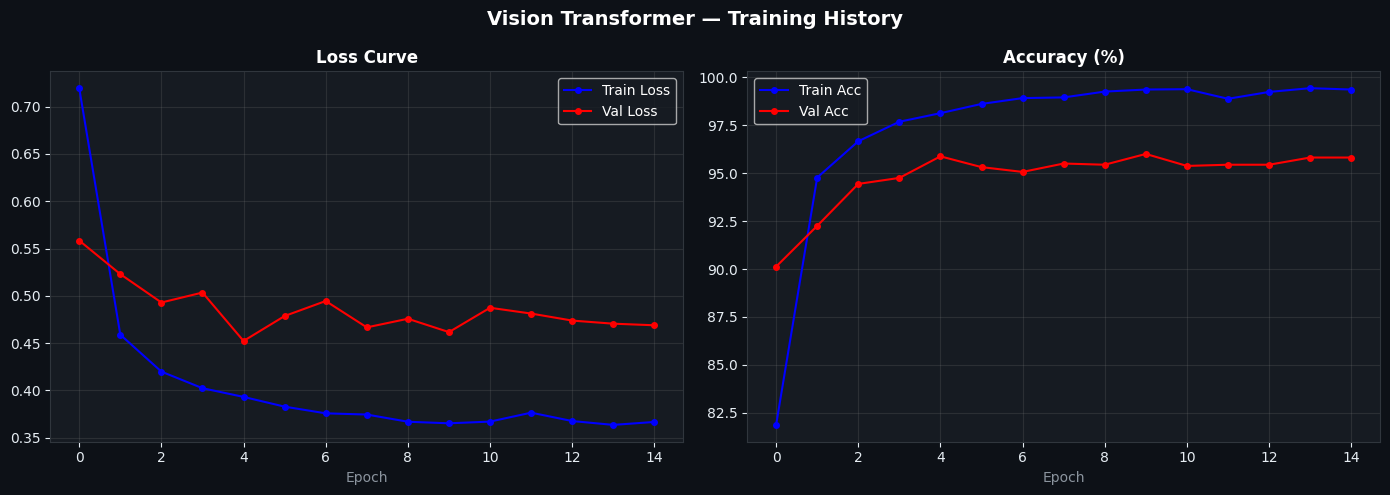

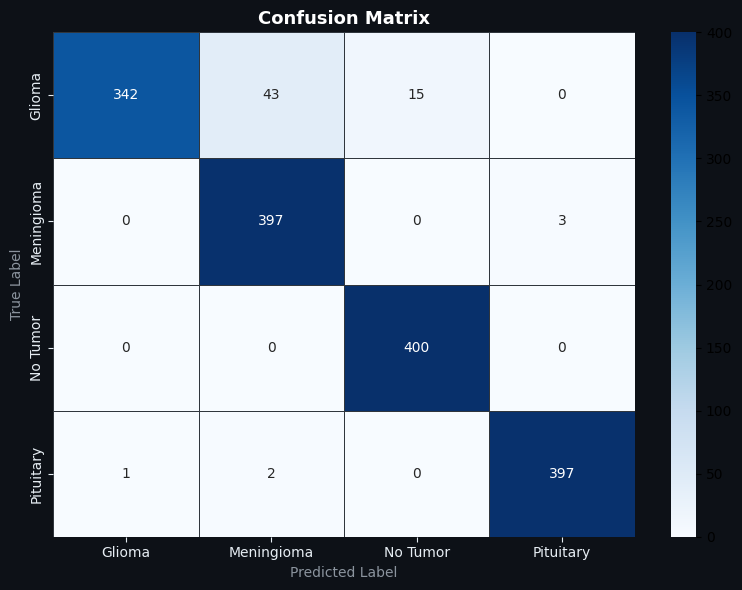


📋 Classification Report:
              precision    recall  f1-score   support

      Glioma       1.00      0.85      0.92       400
  Meningioma       0.90      0.99      0.94       400
    No Tumor       0.96      1.00      0.98       400
   Pituitary       0.99      0.99      0.99       400

    accuracy                           0.96      1600
   macro avg       0.96      0.96      0.96      1600
weighted avg       0.96      0.96      0.96      1600



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0d1117')
fig.suptitle('Vision Transformer — Training History', fontsize=14, fontweight='bold', color='white')
for ax in axes:
    ax.set_facecolor('#161b22')
    for sp in ax.spines.values(): sp.set_color('#30363d')
    ax.tick_params(colors='#e6edf3')
axes[0].plot(history['train_loss'], 'b-o', label='Train Loss', markersize=4)
axes[0].plot(history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Loss Curve', color='white', fontweight='bold')
axes[0].set_xlabel('Epoch', color='#8b949e')
axes[0].legend(facecolor='#161b22', labelcolor='white')
axes[0].grid(True, alpha=0.2, color='gray')
axes[1].plot(history['train_acc'], 'b-o', label='Train Acc', markersize=4)
axes[1].plot(history['val_acc'],   'r-o', label='Val Acc',   markersize=4)
axes[1].set_title('Accuracy (%)', color='white', fontweight='bold')
axes[1].set_xlabel('Epoch', color='#8b949e')
axes[1].legend(facecolor='#161b22', labelcolor='white')
axes[1].grid(True, alpha=0.2, color='gray')
plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

cm = confusion_matrix(final_labels, final_preds)
plt.figure(figsize=(8, 6), facecolor='#0d1117')
ax = plt.gca(); ax.set_facecolor('#161b22')
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='#30363d')
plt.title('Confusion Matrix', fontsize=13, fontweight='bold', color='white')
plt.ylabel('True Label', color='#8b949e')
plt.xlabel('Predicted Label', color='#8b949e')
plt.tick_params(colors='#e6edf3')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

print('\n📋 Classification Report:')
print(classification_report(final_labels, final_preds, target_names=CLASS_NAMES))

## 🔥 Cell 8 — GradCAM Setup

In [ ]:
class GradCAMViT:
    def __init__(self, model):
        self.model       = model
        self.gradients   = None
        self.activations = None
        target = model.vit.blocks[-1].norm1
        target.register_forward_hook(self._fwd)
        target.register_full_backward_hook(self._bwd)

    def _fwd(self, m, inp, out): self.activations = out
    def _bwd(self, m, gi,  go):  self.gradients   = go[0]

    def generate(self, img_tensor, cls_idx=None):
        self.model.eval()
        t   = img_tensor.clone().requires_grad_(True)
        out = self.model(t)
        if cls_idx is None:
            cls_idx = out.argmax(1).item()
        self.model.zero_grad()
        one_hot = torch.zeros_like(out)
        one_hot[0][cls_idx] = 1
        out.backward(gradient=one_hot)
        weights = self.gradients.mean(dim=[0, 2])
        cam     = (weights.unsqueeze(-1) * self.activations[0]).sum(1)
        cam     = cam[1:].detach().cpu().numpy()
        n       = int(len(cam) ** 0.5)
        cam     = cam.reshape(n, n)
        cam     = np.maximum(cam, 0)
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam     = cv2.resize(cam, (224, 224))
        return cam, cls_idx

print('✅ GradCAM ready!')

✅ GradCAM ready!


## 🔬 Cell 9 — Upload Brain MRI & Get Full Report
**Run → Upload any brain MRI image → Get full diagnosis with heatmap!**

In [ ]:
import torch
from google.colab import files as colab_files

# Define TRAIN_DIR and TEST_DIR based on typical Kaggle dataset path
# (These are usually set by cell-2 after dataset download)
TRAIN_DIR = '/kaggle/input/brain-tumor-mri-dataset/Training'
TEST_DIR  = '/kaggle/input/brain-tumor-mri-dataset/Testing'

# Re-define CONFIG for standalone execution in this cell
# This is a copy from cell-3 to ensure all necessary variables are available.
CONFIG = {
    'train_dir'   : TRAIN_DIR,
    'test_dir'    : TEST_DIR,
    'model_name'  : 'vit_base_patch16_224',
    'num_classes' : 4,
    'img_size'    : 224,
    'batch_size'  : 32,
    'epochs'      : 15,
    'lr'          : 2e-4,
    'weight_decay': 1e-5,
    'save_path'   : 'brain_tumor_vit_best.pth',
    'num_workers' : 2,
    'device'      : 'cuda' if torch.cuda.is_available() else 'cpu',
}

# Also re-define CLASS_NAMES and CLASS_INFO if they are not globally accessible
CLASS_NAMES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

CLASS_INFO = {
    'Glioma': {
        'emoji'        : '🔴',
        'tumor'        : True,
        'brain_region' : 'Cerebrum / Brainstem / Cerebellum',
        'description'  : 'Tumor from glial cells of the brain/spinal cord. Affects thinking, movement, and bodily functions.',
        'affected_part': 'CEREBRUM (thought, memory, movement), BRAINSTEM (breathing, heart rate), or CEREBELLUM (balance).',
        'severity'     : 'HIGH ⚠️  — Can be malignant (cancerous)',
        'cure_chance'  : {
            'label'  : 'Moderate to Low',
            'percent': '30–60%',
            'details': 'Grade I–II: 60–80% 5-yr survival.\nGrade III: ~30–40%.\nGrade IV (GBM): ~5–10%.\nEarly detection improves outcomes significantly.'
        },
        'treatments': ['Surgical resection', 'Radiation therapy', 'Chemotherapy (Temozolomide)', 'Immunotherapy', 'Tumor Treating Fields (TTFields)'],
    },
    'Meningioma': {
        'emoji'        : '🟡',
        'tumor'        : True,
        'brain_region' : 'Brain Surface / Skull Base / Spinal Cord Covering',
        'description'  : 'Tumor from the meninges — membranes covering the brain. Usually benign and slow-growing.',
        'affected_part': 'OUTER BRAIN SURFACE or SKULL BASE. Presses on nearby regions causing headaches, vision issues, or weakness.',
        'severity'     : 'MODERATE 🟡 — Usually benign; malignant in ~3% of cases',
        'cure_chance'  : {
            'label'  : 'High',
            'percent': '70–90%',
            'details': 'Grade I (Benign): 90%+ survival with surgery.\nGrade II: 50–70% recurrence-free at 5 yrs.\nGrade III: ~50% 5-yr survival.'
        },
        'treatments': ['Active surveillance', 'Surgical resection', 'Gamma Knife / CyberKnife', 'Radiation therapy', 'Symptom medications'],
    },
    'No Tumor': {
        'emoji'        : '✅',
        'tumor'        : False,
        'brain_region' : 'N/A — All regions appear normal',
        'description'  : 'No tumor or abnormality detected. Brain structure is within normal limits.',
        'affected_part': 'No affected region. CEREBRUM, CEREBELLUM, BRAINSTEM — all appear structurally normal.',
        'severity'     : 'NORMAL ✅ — No pathology detected',
        'cure_chance'  : {
            'label'  : 'N/A',
            'percent': '100%',
            'details': 'No tumor detected. No treatment required.'
        },
        'treatments': ['No tumor-specific treatment needed', 'Routine annual MRI monitoring', 'Regular health check-ups'],
    },
    'Pituitary': {
        'emoji'        : '🟡',
        'tumor'        : True,
        'brain_region' : 'Pituitary Gland — Base of Brain (Sella Turcica)',
        'description'  : "Tumor of the pituitary gland — the body's master hormone gland. Usually benign.",
        'affected_part': 'PITUITARY GLAND (sella turcica). May press on OPTIC CHIASM (vision) or HYPOTHALAMUS (body regulation).',
        'severity'     : 'MODERATE 🟡 — Usually benign; significant hormonal effects',
        'cure_chance'  : {
            'label'  : 'High',
            'percent': '75–95%',
            'details': 'Microadenomas (<10mm): 85–95% cure with surgery.\nMacroadenomas: 50–70%.\nProlactinomas: 70–80% controlled with medication alone.'
        },
        'treatments': ['Dopamine agonists (Cabergoline)', 'Transsphenoidal surgery', 'Gamma Knife radiosurgery', 'Hormone replacement', 'MRI monitoring'],
    },
}

# Re-define val_tf for standalone execution in this cell
from torchvision import transforms
val_tf = transforms.Compose([
    transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Re-define BrainTumorViT and model (using timm) for standalone execution
import torch.nn as nn
import timm

class BrainTumorViT(nn.Module):
    def __init__(self, num_classes=4, pretrained=True):
        super().__init__()
        self.vit = timm.create_model(
            CONFIG['model_name'], pretrained=pretrained, num_classes=0
        )
        in_features = self.vit.num_features
        self.classifier = nn.Sequential(
            nn.LayerNorm(in_features),
            nn.Dropout(0.3),
            nn.Linear(in_features, 512),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.vit(x))

model = BrainTumorViT(num_classes=CONFIG['num_classes']).to(CONFIG['device'])

# Re-define GradCAMViT for standalone execution
import numpy as np
import cv2

class GradCAMViT:
    def __init__(self, model):
        self.model       = model
        self.gradients   = None
        self.activations = None
        target = model.vit.blocks[-1].norm1
        target.register_forward_hook(self._fwd)
        target.register_full_backward_hook(self._bwd)

    def _fwd(self, m, inp, out): self.activations = out
    def _bwd(self, m, gi,  go):  self.gradients   = go[0]

    def generate(self, img_tensor, cls_idx=None):
        self.model.eval()
        t   = img_tensor.clone().requires_grad_(True)
        out = self.model(t)
        if cls_idx is None:
            cls_idx = out.argmax(1).item()
        self.model.zero_grad()
        one_hot = torch.zeros_like(out)
        one_hot[0][cls_idx] = 1
        out.backward(gradient=one_hot)
        weights = self.gradients.mean(dim=[0, 2])
        cam     = (weights.unsqueeze(-1) * self.activations[0]).sum(1)
        cam     = cam[1:].detach().cpu().numpy()
        n       = int(len(cam) ** 0.5)
        cam     = cam.reshape(n, n)
        cam     = np.maximum(cam, 0)
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam     = cv2.resize(cam, (224, 224))
        return cam, cls_idx


def predict_image():
    print('📤 Upload a brain MRI image (JPG / PNG):')
    uploaded = colab_files.upload()
    if not uploaded:
        print('❌ No file uploaded.'); return
    img_path = list(uploaded.keys())[0]

    ckpt = torch.load(CONFIG['save_path'], map_location=CONFIG['device'])
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    print(f'✅ Model loaded  (val acc: {ckpt["val_acc"]:.2f}%)')

    img_pil    = Image.open(img_path).convert('RGB')
    img_tensor = val_tf(img_pil).unsqueeze(0).to(CONFIG['device'])

    with torch.no_grad():
        logits = model(img_tensor)
        probs  = torch.softmax(logits, dim=1)[0]
    pred_idx   = probs.argmax().item()
    pred_class = CLASS_NAMES[pred_idx]
    confidence = probs[pred_idx].item()
    info       = CLASS_INFO[pred_class]
    is_tumor   = info['tumor']

    gradcam       = GradCAMViT(model)
    heatmap, _    = gradcam.generate(img_tensor.clone(), pred_idx)
    img_224       = np.array(img_pil.resize((224, 224)))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay       = cv2.addWeighted(img_224, 0.55, heatmap_color, 0.45, 0)

    bg      = '#FFFFFF'
    panel_c = '#000000'
    text_c  = '#000000'
    sub_c   = '#8b949e'
    accent  = '#ef4444' if is_tumor else '#22c55e'

    fig = plt.figure(figsize=(20, 12))
    fig.patch.set_facecolor(bg)
    gs  = GridSpec(2, 4, figure=fig, hspace=0.4, wspace=0.3)

    def styled_ax(ax, title=''):
        ax.set_facecolor(panel_c)
        for sp in ax.spines.values(): sp.set_color(accent)
        ax.tick_params(colors=text_c)
        if title:
            ax.set_title(title, color=text_c, fontsize=11, fontweight='bold', pad=8)

    ax1 = fig.add_subplot(gs[0, 0])
    styled_ax(ax1, '🖼  Original MRI Scan')
    ax1.imshow(img_pil); ax1.set_xticks([]); ax1.set_yticks([])

    ax2 = fig.add_subplot(gs[0, 1])
    styled_ax(ax2, '🔥  Attention Heatmap')
    ax2.imshow(heatmap_color); ax2.set_xticks([]); ax2.set_yticks([])
    cbar = plt.colorbar(plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(0, 1)),
                        ax=ax2, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(colors=sub_c, labelsize=7)
    cbar.set_label('Intensity', color=sub_c, fontsize=8)

    ax3 = fig.add_subplot(gs[0, 2])
    styled_ax(ax3, '📍  Tumor Region Overlay')
    ax3.imshow(overlay); ax3.set_xticks([]); ax3.set_yticks([])

    ax4 = fig.add_subplot(gs[0, 3])
    ax4.set_facecolor(panel_c)
    for sp in ax4.spines.values(): sp.set_color(accent)
    ax4.tick_params(colors=text_c, labelsize=9)
    ax4.set_title('📊  Class Probabilities', color=text_c, fontsize=11, fontweight='bold', pad=8)
    bar_colors = ['#ef4444' if n != 'No Tumor' else '#22c55e' for n in CLASS_NAMES]
    bars = ax4.barh(CLASS_NAMES, [probs[i].item()*100 for i in range(4)],
                    color=bar_colors, edgecolor='#30363d', linewidth=0.8, height=0.55)
    ax4.set_xlim(0, 108)
    ax4.set_xlabel('Probability (%)', color=sub_c, fontsize=9)
    for i, (bar, prob) in enumerate(zip(bars, probs)):
        ax4.text(bar.get_width()+1, bar.get_y()+bar.get_height()/2,
                 f'{prob.item()*100:.1f}%', va='center', color=text_c, fontsize=9,
                 fontweight='bold' if i == pred_idx else 'normal')
        if i == pred_idx: bars[i].set_edgecolor('white'); bars[i].set_linewidth(2)
    ax4.set_yticklabels(CLASS_NAMES, color=text_c)
    ax4.set_facecolor(panel_c)

    ax5 = fig.add_subplot(gs[1, :])
    ax5.set_facecolor(panel_c)
    for sp in ax5.spines.values(): sp.set_color(accent)
    ax5.axis('off')

    col1 = (f'DIAGNOSIS\n  {info["emoji"]}  {pred_class}\n\n'
            f'CONFIDENCE\n  {confidence*100:.2f}%\n\n'
            f'TUMOR DETECTED\n  {"YES ⚠️  — Seek medical attention" if is_tumor else "NO ✅  — Normal scan"}\n\n'
            f'SEVERITY\n  {info["severity"]}')
    col2 = (f'BRAIN REGION AFFECTED\n  {info["brain_region"]}\n\n'
            f'PART OF BRAIN\n  {info["affected_part"][:120]}\n\n'
            f'CURE POSSIBILITY\n  {info["cure_chance"]["label"]}  ({info["cure_chance"]["percent"]})')
    col3 = ('TREATMENTS\n' + '\n'.join(f'  ✔  {t}' for t in info['treatments']) +
            f'\n\nCURE DETAILS\n  {info["cure_chance"]["details"]}')

    box = dict(boxstyle='round,pad=0.5', facecolor='#21262d', edgecolor=accent, linewidth=1.2)
    for x, col in zip([0.01, 0.34, 0.67], [col1, col2, col3]):
        ax5.text(x, 0.97, col, transform=ax5.transAxes, color=text_c,
                 fontsize=9.5, verticalalignment='top', fontfamily='monospace', bbox=box)

    status = '🔴  TUMOR DETECTED' if is_tumor else '✅  NO TUMOR DETECTED'
    fig.suptitle(f'🧠  BRAIN TUMOR ANALYSIS  |  {status}  |  {pred_class}  |  {confidence*100:.1f}% Confidence',
                 fontsize=14, fontweight='bold', color=accent, y=0.99, backgroundcolor=panel_c)
    plt.savefig('prediction_result.png', dpi=150, bbox_inches='tight', facecolor=bg)
    plt.show()

    W = 65
    print('\n' + '═'*W)
    print(f'{"🧠  BRAIN TUMOR ANALYSIS REPORT":^{W}}')
    print('═'*W)
    print(f'  Diagnosis         : {info["emoji"]} {pred_class}')
    print(f'  Confidence        : {confidence*100:.2f}%')
    print(f'  Tumor Detected    : {"YES ⚠️" if is_tumor else "NO ✅"}')
    print(f'  Severity          : {info["severity"]}')
    print('─'*W)
    print(f'  Brain Region      : {info["brain_region"]}')
    print(f'  Part Affected     : {info["affected_part"]}')
    print('─'*W)
    print(f'  Cure Possibility  : {info["cure_chance"]["label"]}  ({info["cure_chance"]["percent"]})')
    for line in info['cure_chance']['details'].split('\n'): print(f'    {line}')
    print('─'*W)
    print('  Treatments:')
    for t in info['treatments']: print(f'    ✔  {t}')
    print('─'*W)
    print('  Class Probabilities:')
    for i, (name, prob) in enumerate(zip(CLASS_NAMES, probs)):
        bar   = '█' * int(prob.item() * 30)
        arrow = '  ◄ PREDICTED' if i == pred_idx else ''
        print(f'    {name:<15}: {prob.item()*100:5.1f}%  {bar}{arrow}')
    print('═'*W)
    print('  ⚠️  DISCLAIMER: AI-assisted analysis only.')
    print('      Consult a qualified neurologist / radiologist.')
    print('═'*W)


predict_image()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

📤 Upload a brain MRI image (JPG / PNG):


Saving Te-gl_39.jpg to Te-gl_39 (1).jpg


FileNotFoundError: [Errno 2] No such file or directory: 'brain_tumor_vit_best.pth'

## 💾 Cell 10 — Save to Google Drive (Optional)

In [ ]:
from google.colab import drive
import shutil
drive.mount('/content/drive')
save_dir = '/content/drive/MyDrive/BrainTumorViT'
os.makedirs(save_dir, exist_ok=True)
for fname in [CONFIG['save_path'], 'training_history.png', 'confusion_matrix.png', 'prediction_result.png']:
    if os.path.exists(fname):
        shutil.copy(fname, os.path.join(save_dir, fname))
        print(f'✅ {fname} → saved to Google Drive/BrainTumorViT/')
print('\n🎉 All files saved!')

---
## 📋 Cell Order Reference

| Cell | Purpose | Notes |
|---|---|---|
| 1 | Install libraries | Run once |
| **2** | **Download dataset via Kaggle API** | Upload `kaggle.json` when prompted |
| 3 | Config + class info | Run once |
| 4 | Data loaders + preview | Run once |
| 5 | Build ViT model | Run once |
| 6 | **Train** (~20–30 min on T4) | Run once |
| 7 | Training curves + confusion matrix | Run once |
| 8 | GradCAM setup | Run once |
| **9** | **Upload MRI → Full Report** | Re-run for each image |
| 10 | Save to Google Drive | Optional |

---
> ⚠️ **Medical Disclaimer:** For educational purposes only.